<a href="https://colab.research.google.com/github/tamkj/CapStoneETKJ/blob/main/CapStone_Sport.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Project CapStone
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/athlete_events.csv')
df.info()

dfSumm = df[df["Season"] !="Winter"] # delete Winter Seasons
dfSumm.info()
dfSumm.to_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/SummerOlympics_Data.csv', index=False) #export to CVS


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB
<class 'pandas.core.frame.DataFrame'>
Index: 22255

In [ ]:
# drop Games, Season and Team as info in both column is not necessary for the analysis.
dfSumm = dfSumm.drop(columns=["Games", "Season", "Team"])
dfSumm.info()

<class 'pandas.core.frame.DataFrame'>
Index: 222552 entries, 0 to 271110
Data columns (total 12 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      222552 non-null  int64  
 1   Name    222552 non-null  object 
 2   Sex     222552 non-null  object 
 3   Age     213363 non-null  float64
 4   Height  170695 non-null  float64
 5   Weight  168698 non-null  float64
 6   NOC     222552 non-null  object 
 7   Year    222552 non-null  int64  
 8   City    222552 non-null  object 
 9   Sport   222552 non-null  object 
 10  Event   222552 non-null  object 
 11  Medal   34088 non-null   object 
dtypes: float64(3), int64(2), object(7)
memory usage: 22.1+ MB


In [ ]:
# Merge Host_Country from Host_List.csv
hosts = pd.read_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/Host_List.csv')
dfSumm2 = dfSumm.merge(hosts, on='City', how='left')
dfSumm2.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222552 entries, 0 to 222551
Data columns (total 13 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ID        222552 non-null  int64  
 1   Name      222552 non-null  object 
 2   Sex       222552 non-null  object 
 3   Age       213363 non-null  float64
 4   Height    170695 non-null  float64
 5   Weight    168698 non-null  float64
 6   NOC       222552 non-null  object 
 7   Year      222552 non-null  int64  
 8   City      222552 non-null  object 
 9   Sport     222552 non-null  object 
 10  Event     222552 non-null  object 
 11  Medal     34088 non-null   object 
 12  Host_Cty  222552 non-null  object 
dtypes: float64(3), int64(2), object(8)
memory usage: 22.1+ MB


In [ ]:
# Merge NOC_Country from noc_regions2.csv
noc_cty = pd.read_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/noc_regions2.csv')
dfSumm2 = dfSumm2.merge(noc_cty, on='NOC', how='left')
dfSumm2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222552 entries, 0 to 222551
Data columns (total 14 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ID        222552 non-null  int64  
 1   Name      222552 non-null  object 
 2   Sex       222552 non-null  object 
 3   Age       213363 non-null  float64
 4   Height    170695 non-null  float64
 5   Weight    168698 non-null  float64
 6   NOC       222552 non-null  object 
 7   Year      222552 non-null  int64  
 8   City      222552 non-null  object 
 9   Sport     222552 non-null  object 
 10  Event     222552 non-null  object 
 11  Medal     34088 non-null   object 
 12  Host_Cty  222552 non-null  object 
 13  NOC_Cty   222552 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 23.8+ MB


In [ ]:
# export dataframe to cvs
dfSumm2.to_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/SummerOlympics_1024_0.csv', index=False)

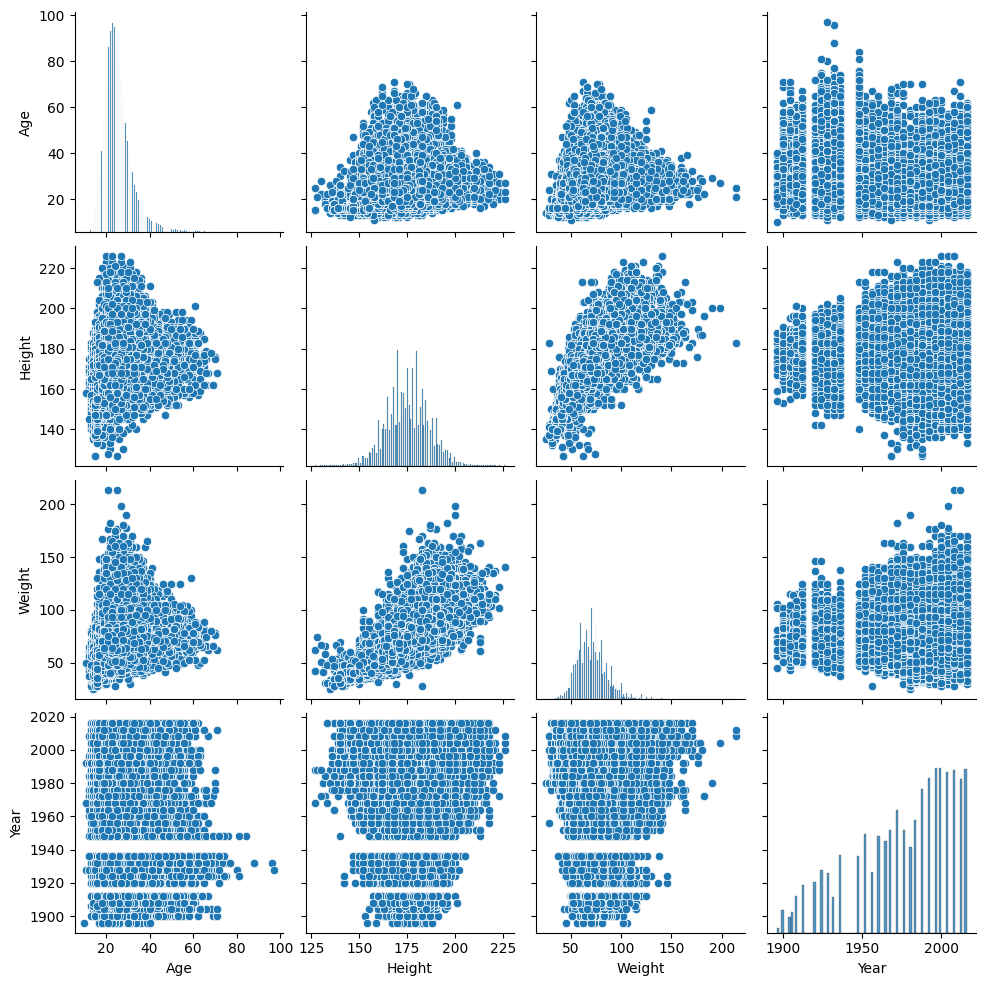

In [ ]:
# Scatter plot before managing Medals
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(dfSumm2.drop(columns=["ID"]))

In [ ]:
# Add a column if athlete won a medal
dfSumm2['won_medal'] = dfSumm2['Medal'].notna()
dfSumm2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222552 entries, 0 to 222551
Data columns (total 15 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ID         222552 non-null  int64  
 1   Name       222552 non-null  object 
 2   Sex        222552 non-null  object 
 3   Age        213363 non-null  float64
 4   Height     170695 non-null  float64
 5   Weight     168698 non-null  float64
 6   NOC        222552 non-null  object 
 7   Year       222552 non-null  int64  
 8   City       222552 non-null  object 
 9   Sport      222552 non-null  object 
 10  Event      222552 non-null  object 
 11  Medal      34088 non-null   object 
 12  Host_Cty   222552 non-null  object 
 13  NOC_Cty    222552 non-null  object 
 14  won_medal  222552 non-null  bool   
dtypes: bool(1), float64(3), int64(2), object(9)
memory usage: 24.0+ MB


In [ ]:
# this cell is for loading CSV after kernal was terminated. Can ignore cell
# import pandas as pd
# from google.colab import drive
# drive.mount('/content/drive')

# dfSumm2 = pd.read_csv('/content/drive/MyDrive/1.NTUC/11.CapStone/SummerOlympics_1024_0.csv')
# dfSumm2.info()


In [ ]:
import pandas as pd
import numpy as np

# ============================================================
# 0. CLEANING
# ============================================================
dfSumm2["won_medal"] = dfSumm2["won_medal"].astype(str).str.upper().eq("TRUE")
dfSumm2["Age"]       = pd.to_numeric(dfSumm2["Age"],    errors="coerce")
dfSumm2["Height"]    = pd.to_numeric(dfSumm2["Height"], errors="coerce")
dfSumm2["Weight"]    = pd.to_numeric(dfSumm2["Weight"], errors="coerce")
dfSumm2["Year"]      = pd.to_numeric(dfSumm2["Year"],   errors="coerce").astype("Int64")

# Derived keys
dfSumm2["AthleteKey"] = dfSumm2["ID"]
dfSumm2["NOCKey"]     = dfSumm2["NOC"]
dfSumm2["SportKey"]   = dfSumm2["Sport"]
dfSumm2["EventKey"]   = dfSumm2["Event"]
dfSumm2["EditionKey"] = dfSumm2["Year"]
dfSumm2["MedalKey"]   = dfSumm2["Medal"].fillna("None")

# ============================================================
# 1. DERIVED FIELDS (BMI, bands)
# ============================================================
dfSumm2["BMI"] = np.where(
    (dfSumm2["Height"] > 0) & (dfSumm2["Weight"] > 0),
    dfSumm2["Weight"] / (dfSumm2["Height"] / 100) ** 2,
    np.nan,
)

dfSumm2["AgeBand"] = pd.cut(
    dfSumm2["Age"],
    bins=[0, 15, 18, 21, 24, 27, 30, 33, 36, 40, 45, 50, 60, 100],
    labels=["<=15", "16-18", "19-21", "22-24", "25-27", "28-30",
            "31-33", "34-36", "37-40", "41-45", "46-50", "51-60", "60+"],
)

dfSumm2["BMIBand"] = pd.cut(
    dfSumm2["BMI"],
    bins=[0, 18, 20, 22, 24, 26, 28, 30, 35, 100],
    labels=["<18", "18-20", "20-22", "22-24", "24-26",
            "26-28", "28-30", "30-35", "35+"],
)

# ============================================================
# 2. FACT TABLE  (thin: keys + athlete-level facts only)
#    EventKey and SportKey act as degenerate dimensions —
#    use them directly in PowerBI slicers/filters.
# ============================================================
fact = dfSumm2[[
    # Foreign keys / degenerate dimensions
    "AthleteKey", "NOCKey", "SportKey", "EventKey", "EditionKey", "MedalKey",
    # Athlete-level degenerate attributes
    "Name", "Sex", "Age", "AgeBand", "Height", "Weight", "BMI", "BMIBand",
    # Row-level fact flag
    "won_medal",
]].copy()

# ============================================================
# 3. DIMENSION TABLES  (DimNOC, DimEdition, DimMedal only)
# ============================================================
dim_noc = dfSumm2[["NOCKey", "NOC_Cty"]].drop_duplicates("NOCKey")

dim_edition = dfSumm2[["EditionKey", "Year", "City", "Host_Cty"]].drop_duplicates("EditionKey")

dim_medal = pd.DataFrame({
    "MedalKey": ["Gold", "Silver", "Bronze", "None"],
    "Medal":    ["Gold", "Silver", "Bronze", "None"],
    "IsMedal":  [True, True, True, False],
})

# ============================================================
# 4. IOC-CORRECT MEDAL BASE
#    One row = one medal actually awarded per IOC record.
#    Collapses team sports to 1; keeps sweeps as 2 or 3.
# ============================================================
medals_dedup = (
    dfSumm2[dfSumm2["won_medal"] & dfSumm2["Medal"].notna()]
      .drop_duplicates(["NOC", "Year", "Event", "Medal"])
      .copy()
)

# ============================================================
# 5. AGGREGATE TABLES
# ============================================================

# ---- Table 8: AggNOCEdition (Q1, Q2) ----
base_noc = (
    dfSumm2.groupby(["Year", "NOC"])
          .agg(
              AthletesEntered=("ID", "nunique"),
              DistinctSports=("Sport", "nunique"),
          )
          .reset_index()
)

medals_by_noc_year = (
    medals_dedup.groupby(["Year", "NOC"])
                .size()
                .reset_index(name="MedalCount")
)

agg_noc_edition = base_noc.merge(
    medals_by_noc_year, on=["Year", "NOC"], how="left"
)
agg_noc_edition["MedalCount"] = (
    agg_noc_edition["MedalCount"].fillna(0).astype(int)
)

# Host flag: map Host_Cty -> Host NOC (mode per edition)
host_map = (
    dfSumm2.groupby(["Year", "Host_Cty"])["NOC"]
          .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
          .reset_index()
)
host_map.columns = ["Year", "Host_Cty", "HostNOC"]

agg_noc_edition = agg_noc_edition.merge(
    host_map[["Year", "HostNOC"]].drop_duplicates(),
    on="Year", how="left",
)
agg_noc_edition["IsHostNOC"] = (
    agg_noc_edition["NOC"] == agg_noc_edition["HostNOC"]
)

# ---- Table 9: AggSportEdition (Q3) ----
base_sport = (
    dfSumm2.groupby(["Year", "Sport"])
          .agg(
              DistinctNOCs=("NOC", "nunique"),
              AthletesEntered=("ID", "nunique"),
          )
          .reset_index()
)

medals_by_sport_year = (
    medals_dedup.groupby(["Year", "Sport"])
                .size()
                .reset_index(name="MedalCount")
)

agg_sport_edition = base_sport.merge(
    medals_by_sport_year, on=["Year", "Sport"], how="left"
)
agg_sport_edition["MedalCount"] = (
    agg_sport_edition["MedalCount"].fillna(0).astype(int)
)

# ---- Table 9b: AggSportGrowth (Q3 helper) ----
first_last = (
    agg_sport_edition.sort_values("Year")
        .groupby("Sport")
        .agg(
            FirstYear=("Year", "min"),
            LastYear=("Year", "max"),
            FirstNOCs=("DistinctNOCs", "first"),
            LastNOCs=("DistinctNOCs", "last"),
        )
        .reset_index()
)
first_last["AbsGrowth"] = first_last["LastNOCs"] - first_last["FirstNOCs"]
first_last["PctGrowth"] = np.where(
    first_last["FirstNOCs"] > 0,
    first_last["AbsGrowth"] / first_last["FirstNOCs"],
    np.nan,
)
year_span = (first_last["LastYear"] - first_last["FirstYear"]).replace(0, np.nan)
first_last["CAGR"] = (
    (first_last["LastNOCs"] / first_last["FirstNOCs"]) ** (1 / year_span) - 1
)

# ---- Table 10: AggAgeMedal (Q4) ----
# Metric is ATHLETE-level medal rate (each athlete's medal
# counted once). Correct framing for "given an athlete of age X,
# what is the chance they medalled?" — not event-level counts.
agg_age_medal = (
    dfSumm2.dropna(subset=["Age"])
        .groupby(["Sport", "AgeBand"], observed=True)
        .agg(
            Athletes=("ID", "nunique"),
            AthletesWithMedal=("won_medal", "sum"),
        )
        .reset_index()
)
agg_age_medal["AthleteMedalRate"] = (
    agg_age_medal["AthletesWithMedal"] / agg_age_medal["Athletes"]
)

# ---- Table 11: AggProfileMedal (Q5) ----
# Same athlete-level framing as Table 10.
prof = dfSumm2.dropna(subset=["BMI"]).copy()
agg_profile_medal = (
    prof.groupby(["Sport", "Sex", "BMIBand"], observed=True)
        .agg(
            Athletes=("ID", "nunique"),
            AthletesWithMedal=("won_medal", "sum"),
        )
        .reset_index()
)
agg_profile_medal["AthleteMedalRate"] = (
    agg_profile_medal["AthletesWithMedal"] / agg_profile_medal["Athletes"]
)

# ============================================================
# 6. EXPORT
# ============================================================
tables = {
    "FactParticipation": fact,
    "DimNOC":            dim_noc,
    "DimEdition":        dim_edition,
    "DimMedal":          dim_medal,
    "AggNOCEdition":     agg_noc_edition,     # Table 8  (Q1, Q2)
    "AggSportEdition":   agg_sport_edition,   # Table 9  (Q3)
    "AggSportGrowth":    first_last,          # Table 9b (Q3 helper)
    "AggAgeMedal":       agg_age_medal,       # Table 10 (Q4)
    "AggProfileMedal":   agg_profile_medal,   # Table 11 (Q5)
}

for name, tbl in tables.items():
    tbl.to_csv(f"{name}.csv", index=False)
    print(f"✓ {name}.csv  ({len(tbl):,} rows)")

# ============================================================
# 7. SANITY CHECK
# ============================================================
print("\n--- FactParticipation columns ---")
print(fact.columns.tolist())

print("\n--- IOC-correct medal totals ---")
print("Athlete-level medal rows:", int(dfSumm2["won_medal"].sum()))
print("Distinct IOC medals:     ", len(medals_dedup))

# Jamaica 100m sweep 2012 → expect 3
jam = medals_dedup[
    (medals_dedup["NOC"] == "JAM") &
    (medals_dedup["Year"] == 2012) &
    (medals_dedup["Event"].str.contains("100 metres", na=False))
]
print("Jamaica 100m 2012 medals (expect 3):", len(jam))

# USA Basketball 2012 → expect 1
usa_bb = medals_dedup[
    (medals_dedup["NOC"] == "USA") &
    (medals_dedup["Year"] == 2012) &
    (medals_dedup["Event"] == "Basketball Men's Basketball")
]
print("USA Basketball 2012 medals (expect 1):", len(usa_bb))

✓ FactParticipation.csv  (222,552 rows)
✓ DimNOC.csv  (230 rows)
✓ DimEdition.csv  (29 rows)
✓ DimMedal.csv  (4 rows)
✓ AggNOCEdition.csv  (2,882 rows)
✓ AggSportEdition.csv  (672 rows)
✓ AggSportGrowth.csv  (52 rows)
✓ AggAgeMedal.csv  (478 rows)
✓ AggProfileMedal.csv  (523 rows)

--- FactParticipation columns ---
['AthleteKey', 'NOCKey', 'SportKey', 'EventKey', 'EditionKey', 'MedalKey', 'Name', 'Sex', 'Age', 'AgeBand', 'Height', 'Weight', 'BMI', 'BMIBand', 'won_medal']

--- IOC-correct medal totals ---
Athlete-level medal rows: 34088
Distinct IOC medals:      16052
Jamaica 100m 2012 medals (expect 3): 6
USA Basketball 2012 medals (expect 1): 1
